In [1]:
%matplotlib widget

from t2m import Text2Motion
from utils.get_opt import get_opt
from utils.fixseed import fixseed

import torch
import numpy as np
from os.path import join as pjoin

In [2]:
denoiser_name = "denoiser_example_multi_gpu"
dataset_name = "kit"
generator = Text2Motion(denoiser_name, dataset_name)

opt = generator.opt
wrapper_opt = get_opt(opt.dataset_opt_path, torch.device("cuda"))
mean = np.load(pjoin(wrapper_opt.meta_dir, "mean.npy"))
std = np.load(pjoin(wrapper_opt.meta_dir, "std.npy"))

Reading checkpoints/kit/denoiser_example_multi_gpu/opt.txt
Reading checkpoints/kit/vae_example_multi_gpu/opt.txt
Loading VAE Model vae_example_multi_gpu
Loading Denoiser Model denoiser_example_multi_gpu


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Loaded CLIP text encoder version ViT-B/32
Reading ./checkpoints/kit/Comp_v6_KLD005/opt.txt


### Original

In [14]:
fixseed(42)
src_text = "a person is falling."
m_lens = 64
cfg_scale = 7.5
num_inference_timesteps = 50

init_noise, src_motion, (sa, ta, ca) = generator.generate(src_text,
                                                          m_lens,
                                                          cfg_scale,
                                                          num_inference_timesteps)

In [4]:
fixseed(42)
src_text_2 = "A person executes a fast, snapping high kick with their right leg."
m_lens = 64
cfg_scale = 7.5
num_inference_timesteps = 50

init_noise, src_motion_2, (sa, ta, ca) = generator.generate(src_text_2,
                                                          m_lens,
                                                          cfg_scale,
                                                          num_inference_timesteps)

### Edit - 4 Different Cases

In [12]:
# edit_text = "slowly"
edit_text = "a person is walking while waving his both hands."
src_proportion = 0.2

# # case 1: mirror
# edit_motion = generator.edit(init_noise,
#                              src_text=src_text,
#                              edit_text=edit_text,
#                              edit_mode="mirror",
#                              mirror_mode="lower",
#                              cfg_scale=cfg_scale,
#                              num_inference_timesteps=num_inference_timesteps,
#                              src_sa=sa,
#                              src_ta=ta,
#                              src_ca=ca,
#                              src_proportion=src_proportion)

# # case 2: reweight
# edit_motion = generator.edit(init_noise,
#                              src_text=src_text,
#                              edit_text=src_text,
#                              edit_mode="reweight",
#                              tgt_word="high",
#                              reweight_scale=-1.0,
#                              cfg_scale=cfg_scale,
#                              num_inference_timesteps=num_inference_timesteps,
#                              src_sa=sa,
#                              src_ta=ta,
#                              src_ca=ca,
#                              src_proportion=src_proportion)

# case 3: refine
edit_motion = generator.edit(init_noise,
                             src_text=src_text,
                             edit_text=edit_text,
                             edit_mode="refine",
                             cfg_scale=cfg_scale,
                             num_inference_timesteps=num_inference_timesteps,
                             src_sa=sa,
                             src_ta=ta,
                             src_ca=ca,
                             src_proportion=src_proportion)

# # case 4: word swap
# edit_motion = generator.edit(init_noise,
#                              src_text=src_text,
#                              edit_text=edit_text,
#                              edit_mode="word_swap",
#                              cfg_scale=cfg_scale,
#                              num_inference_timesteps=num_inference_timesteps,
#                              src_sa=sa,
#                              src_ta=None,
#                              src_ca=ca,
#                              src_proportion=src_proportion,
#                              swap_src_proportion=0.2)


### Visualize

In [5]:
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from matplotlib.figure import Figure  # Crucial: Bypasses Jupyter widget hijacking
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
import numpy as np

def plot_3d_motion(kinematic_tree, joints, title, figsize=(7, 7), fps=30, save_path=None):
    title_sp = title.split(' ')
    if len(title_sp) > 20:
        title = '\n'.join([' '.join(title_sp[:10]), ' '.join(title_sp[10:20]), ' '.join(title_sp[20:])])
    elif len(title_sp) > 10:
        title = '\n'.join([' '.join(title_sp[:10]), ' '.join(title_sp[10:])])

    # 1. Prepare data shape
    data = joints.copy().reshape(len(joints), -1, 3)
    
    # Apply your coordinate transformations
    MINS = data.min(axis=0).min(axis=0)
    MAXS = data.max(axis=0).max(axis=0)
    
    height_offset = MINS[1]
    data[:, :, 1] -= height_offset
    trajec = data[:, 0, [0, 2]]

    data[..., 0] -= data[:, 0:1, 0]
    data[..., 2] -= data[:, 0:1, 2]

    # Calculate dynamic data limits (millimeter scale)
    x_min, x_max = data[..., 0].min(), data[..., 0].max()
    y_min, y_max = data[..., 1].min(), data[..., 1].max()
    z_min, z_max = data[..., 2].min(), data[..., 2].max()
    pad = 50.0 

    colors = ['red', 'blue', 'black', 'red', 'blue',
              'darkblue', 'darkblue', 'darkblue', 'darkblue', 'darkblue',
              'darkred', 'darkred', 'darkred', 'darkred', 'darkred']
    frame_number = data.shape[0]

    # Shared drawing core used by both export and live display engines
    def draw_single_frame(index, target_ax, target_fig):
        target_ax.clear() 
        target_ax.set_axis_off()
        target_ax.view_init(elev=120, azim=-90, vertical_axis='z')
        
        # Re-apply boundaries
        target_ax.set_xlim3d([x_min - pad, x_max + pad])
        target_ax.set_ylim3d([y_min - pad, y_max + pad])
        target_ax.set_zlim3d([z_min - pad, z_max + pad])
        target_fig.suptitle(title, fontsize=14)
        
        # Draw floor plane (XZ plane at Y=0)
        minx, maxx = MINS[0] - trajec[index, 0], MAXS[0] - trajec[index, 0]
        minz, maxz = MINS[2] - trajec[index, 1], MAXS[2] - trajec[index, 1]
        verts = [[minx, 0, minz], [minx, 0, maxz], [maxx, 0, maxz], [maxx, 0, minz]]
        xz_plane = Poly3DCollection([verts])
        xz_plane.set_facecolor((0.5, 0.5, 0.5, 0.5))
        target_ax.add_collection3d(xz_plane)
        
        # Draw the tracking trajectory path
        if index > 1:
            target_ax.plot3D(trajec[:index, 0] - trajec[index, 0], np.zeros_like(trajec[:index, 0]),
                             trajec[:index, 1] - trajec[index, 1], linewidth=1.0, color='blue')

        # Draw the joint dots
        target_ax.scatter3D(data[index, :, 0], data[index, :, 1], data[index, :, 2], c='black', s=15)

        # Draw the bones/limbs connecting the joints
        for i, (chain, color) in enumerate(zip(kinematic_tree, colors)):
            linewidth = 4.0 if i < 5 else 2.0
            target_ax.plot3D(data[index, chain, 0], data[index, chain, 1], data[index, chain, 2], linewidth=linewidth, color=color)

    # PASS 1: File Export (Bypasses ipympl backend completely)
    if save_path is not None:
        print(f"-> Exporting animation to: {save_path}")
        fig_save = Figure(figsize=figsize) 
        ax_save = fig_save.add_subplot(111, projection='3d')
        
        ani_save = FuncAnimation(fig_save, draw_single_frame, frames=frame_number, 
                                 fargs=(ax_save, fig_save), blit=False)
        
        if save_path.endswith('.gif'):
            ani_save.save(save_path, writer='pillow', fps=fps)
        elif save_path.endswith('.mp4'):
            ani_save.save(save_path, writer='ffmpeg', fps=fps)
        else:
            raise ValueError("Unsupported format! Save path must end with '.gif' or '.mp4'")
        print("-> Export complete!")

    # PASS 2: Clean Interactive Display Setup (The only figure Jupyter recognizes)
    plt.close('3d_motion_fig') 
    
    fig = plt.figure(num='3d_motion_fig', figsize=figsize)
    ax = fig.add_subplot(111, projection='3d')
    
    ani = FuncAnimation(fig, draw_single_frame, frames=frame_number, fargs=(ax, fig),
                        interval=1000 / fps, repeat=True, blit=False)
    fig.anim = ani 
    
    plt.show()
    return fig

In [6]:
import os
from os.path import join as pjoin
import torch
import numpy as np
from utils.motion_process import recover_from_ric
# from utils.plot_script import plot_3d_motion
from utils.get_opt import get_opt

def plot_t2m(data, text, filename):
    os.makedirs("edit_result", exist_ok=True)
    #data = data[:m_lens[0].item()]
    data = data[:m_lens]
    joint = recover_from_ric(torch.from_numpy(data).float(), opt.joints_num).numpy()
    save_path = pjoin("edit_result", f"{filename}.mp4")
    plot_3d_motion(opt.kinematic_chain, joint, title=text, fps=30, save_path=save_path)
    
    np.save(pjoin("edit_result", f"{filename}_pos.npy"), joint)
    np.save(pjoin("edit_result", f"{filename}_feats.npy"), data)
    
# mean and std for de-normalization
wrapper_opt = get_opt(opt.dataset_opt_path, torch.device('cuda'))
mean = np.load(pjoin(wrapper_opt.meta_dir, 'mean.npy'))
std = np.load(pjoin(wrapper_opt.meta_dir, 'std.npy'))

Reading ./checkpoints/kit/Comp_v6_KLD005/opt.txt


### Plot Motions

-> Exporting animation to: edit_result/src.mp4
-> Export complete!


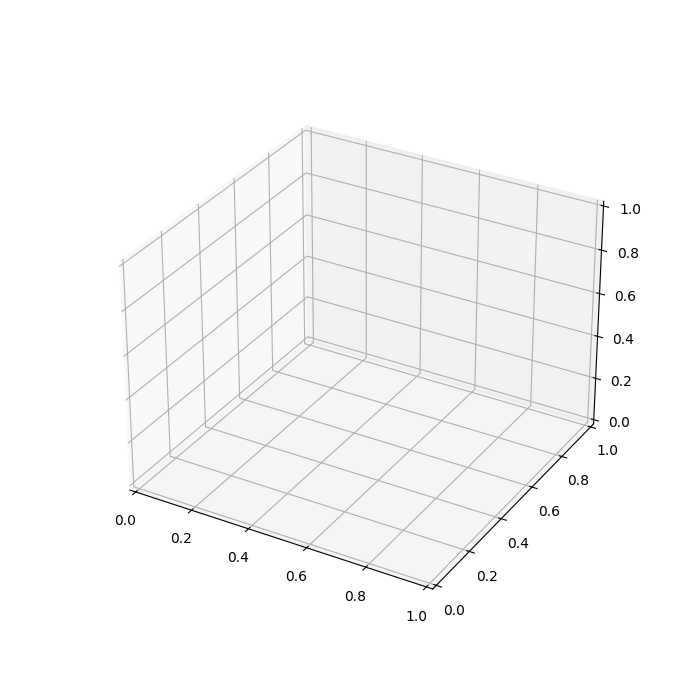

In [15]:
# %matplotlib inline
src_motion_cl = src_motion.clone()
src_motion_cl = src_motion_cl.detach().cpu().numpy() * std + mean
src_motion_plot = plot_t2m(src_motion_cl[0], src_text, "src")

In [8]:
# %matplotlib inline
src_motion_cl_2 = src_motion_2.clone()
src_motion_cl_2 = src_motion_cl_2.detach().cpu().numpy() * std + mean
src_motion_plot_2 = plot_t2m(src_motion_cl_2[0], src_text_2, "src_2")

NameError: name 'src_motion_2' is not defined

-> Exporting animation to: edit_result/edit.mp4
-> Export complete!


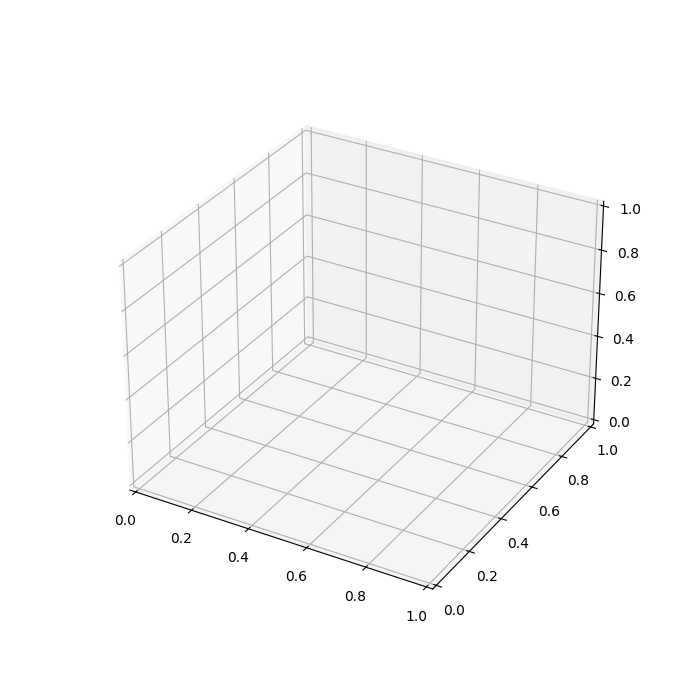

In [13]:
edit_motion_cl = edit_motion.clone()
edit_motion_cl = edit_motion_cl.detach().cpu().numpy() * std + mean
plot_t2m(edit_motion_cl[0], edit_text, "edit")

### Video Visualization

In [11]:
%matplotlib inline

from moviepy import VideoFileClip, clips_array

src_video = VideoFileClip(pjoin("edit_result", "src.mp4"))
edit_video = VideoFileClip(pjoin("edit_result", "edit.mp4"))
final_video = clips_array([[src_video, edit_video]])
final_video.write_videofile(pjoin("edit_result", "final.mp4"))


from IPython.display import Video
Video("edit_result/final.mp4", width=800, height=400)

MoviePy - Building video edit_result/final.mp4.
MoviePy - Writing video edit_result/final.mp4



MoviePy - Done !
MoviePy - video ready edit_result/final.mp4


## Plot Spectrum

In [12]:
import os
import numpy as np
import torch
import matplotlib.pyplot as plt
from os.path import join as pjoin

def plot_spectrum(model_name, motion_sequence, joints_num, dataset_name="default_dataset"):
    # --- FIX 1: CLEAR BACKEND MEMORY IMMEDIATELY ---
    # Prevents stale figure objects from blocking new subplot rendering layers
    
    # 1. CREATE DIRECTORIES & DEFINE PATHS
    save_dir = pjoin("checkpoints", dataset_name, model_name, "analysis")
    os.makedirs(save_dir, exist_ok=True)
    save_path = pjoin(save_dir, "spatial_frequency_spectrum_xyz.png")
    
    # 2. GRACEFULLY HANDLE BOTH PYTORCH TENSORS AND NUMPY ARRAYS
    if isinstance(motion_sequence, torch.Tensor):
        motion_tensor = motion_sequence.clone().detach().float()
    else:
        motion_tensor = torch.from_numpy(np.array(motion_sequence)).float()
        
    # Recover joint positions from the target representation
    joints = recover_from_ric(motion_tensor, joints_num)
    if isinstance(joints, torch.Tensor):
        joints = joints.detach().cpu().numpy()

    frames, num_joints, num_channels = joints.shape # [196, 21, 3]

    # --- CONFIGURATION ---
    window_size = 14  
    step_size = 4     
    num_bins = (window_size // 2) + 1 

    heatmap_x   = np.zeros((num_joints, num_bins - 1))
    heatmap_y   = np.zeros((num_joints, num_bins - 1))
    heatmap_z   = np.zeros((num_joints, num_bins - 1))
    heatmap_xyz = np.zeros((num_joints, num_bins - 1))

    # --- 3. COMPUTE WINDOWED FREQUENCIES ---
    for j in range(num_joints):
        accum_x = np.zeros(num_bins - 1)
        accum_y = np.zeros(num_bins - 1)
        accum_z = np.zeros(num_bins - 1)
        window_count = 0
        
        for start in range(0, frames - window_size + 1, step_size):
            end = start + window_size
            window_count += 1
            
            sig_x = joints[start:end, j, 0]
            sig_x = sig_x - np.mean(sig_x)
            accum_x += np.abs(np.fft.rfft(sig_x))[1:] ** 2
            
            sig_y = joints[start:end, j, 1]
            sig_y = sig_y - np.mean(sig_y)
            accum_y += np.abs(np.fft.rfft(sig_y))[1:] ** 2
            
            sig_z = joints[start:end, j, 2]
            sig_z = sig_z - np.mean(sig_z)
            accum_z += np.abs(np.fft.rfft(sig_z))[1:] ** 2
                
        heatmap_x[j, :]   = accum_x / window_count
        heatmap_y[j, :]   = accum_y / window_count
        heatmap_z[j, :]   = accum_z / window_count
        heatmap_xyz[j, :] = (accum_x + accum_y + accum_z) / window_count
        
    # --- 4. COMPUTE & APPEND THE GLOBAL ROWS ---
    plots_data = {
        'XYZ Combined Power': np.vstack([heatmap_xyz, np.mean(heatmap_xyz, axis=0, keepdims=True)]),
        'X-Axis (Lateral)': np.vstack([heatmap_x, np.mean(heatmap_x, axis=0, keepdims=True)]),
        'Y-Axis (Vertical)': np.vstack([heatmap_y, np.mean(heatmap_y, axis=0, keepdims=True)]),
        'Z-Axis (Forward/Backward)': np.vstack([heatmap_z, np.mean(heatmap_z, axis=0, keepdims=True)])
    }
    
    # --- 5. INITIALIZE THE FIXED 2x2 PLOTTING MATRIX ---
    chosen_cmap = 'turbo' 

    scale_limits = {
        'XYZ Combined Power': 1.75e6,
        'X-Axis (Lateral)': 1.3e5,
        'Y-Axis (Vertical)': 2.5e4,  # Lowered slightly so Bin 2 details glow brighter
        'Z-Axis (Forward/Backward)': 1.6e6
    }
    
    # FIX 2: Modified figure aspect ratio to a safer dimension for browser frames
    fig, axes = plt.subplots(2, 2, figsize=(14, 12))
    fig.suptitle(f'Comprehensive Spatial Frequency Analysis: {model_name}', 
                 fontsize=14, fontweight='bold', y=0.96)
    
    positions = [
        (0, 0, 'XYZ Combined Power'),
        (0, 1, 'X-Axis (Lateral)'),
        (1, 0, 'Y-Axis (Vertical)'),
        (1, 1, 'Z-Axis (Forward/Backward)')
    ]
    
    bins_labels = np.arange(1, num_bins)
    joint_ticks = list(range(0, num_joints, 2))
    all_ticks = joint_ticks + [num_joints]
    all_labels = [str(i) for i in joint_ticks] + ['GLOBAL']
    
    for row, col, key in positions:
        ax = axes[row, col]
        display_matrix = plots_data[key]
        
        max_val = scale_limits.get(key, display_matrix.max())
        if max_val == 0: max_val = 1e-5
        
        im = ax.imshow(display_matrix, cmap=chosen_cmap, aspect='auto', vmin=0, vmax=max_val)
        ax.set_title(key, fontsize=11, fontweight='bold', pad=6)
        ax.axhline(y=num_joints - 0.5, color='white', linewidth=2.5, linestyle='-')
        
        ax.set_xticks(np.arange(len(bins_labels)))
        ax.set_xticklabels(bins_labels)
        ax.set_yticks(all_ticks)
        ax.set_yticklabels(all_labels)
        ax.get_yticklabels()[-1].set_weight('bold')
        
        if col == 0:
            ax.set_ylabel('Joint Index', fontsize=10, fontweight='bold')
        if row == 1:
            ax.set_xlabel('Frequency Bins', fontsize=10)
            
        cbar = fig.colorbar(im, ax=ax, pad=0.02, shrink=0.8, aspect=20)
        cbar.ax.tick_params(labelsize=8)
    
    # --- FIX 3: HARD-CODED POSITIONAL SPACING OVER TIGHT_LAYOUT ---
    # This explicitly locks down the margins so subplots cannot squeeze each other out
    fig.subplots_adjust(left=0.08, right=0.92, bottom=0.08, top=0.90, wspace=0.22, hspace=0.26)
    
    # Save asset
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    print(f"Success! Complete 4-Panel Spectrum plot saved to: {save_path}")
    
    # Render and safely detach
    plt.show()


Success! Complete 4-Panel Spectrum plot saved to: checkpoints/kit/denoiser_example_multi_gpu/analysis/spatial_frequency_spectrum_xyz.png


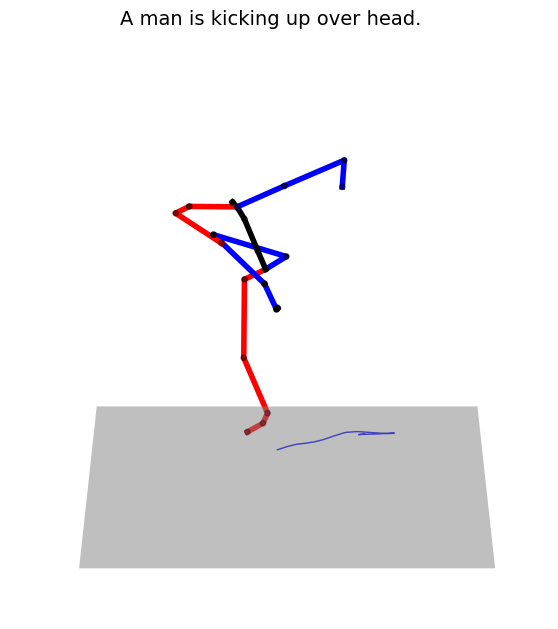

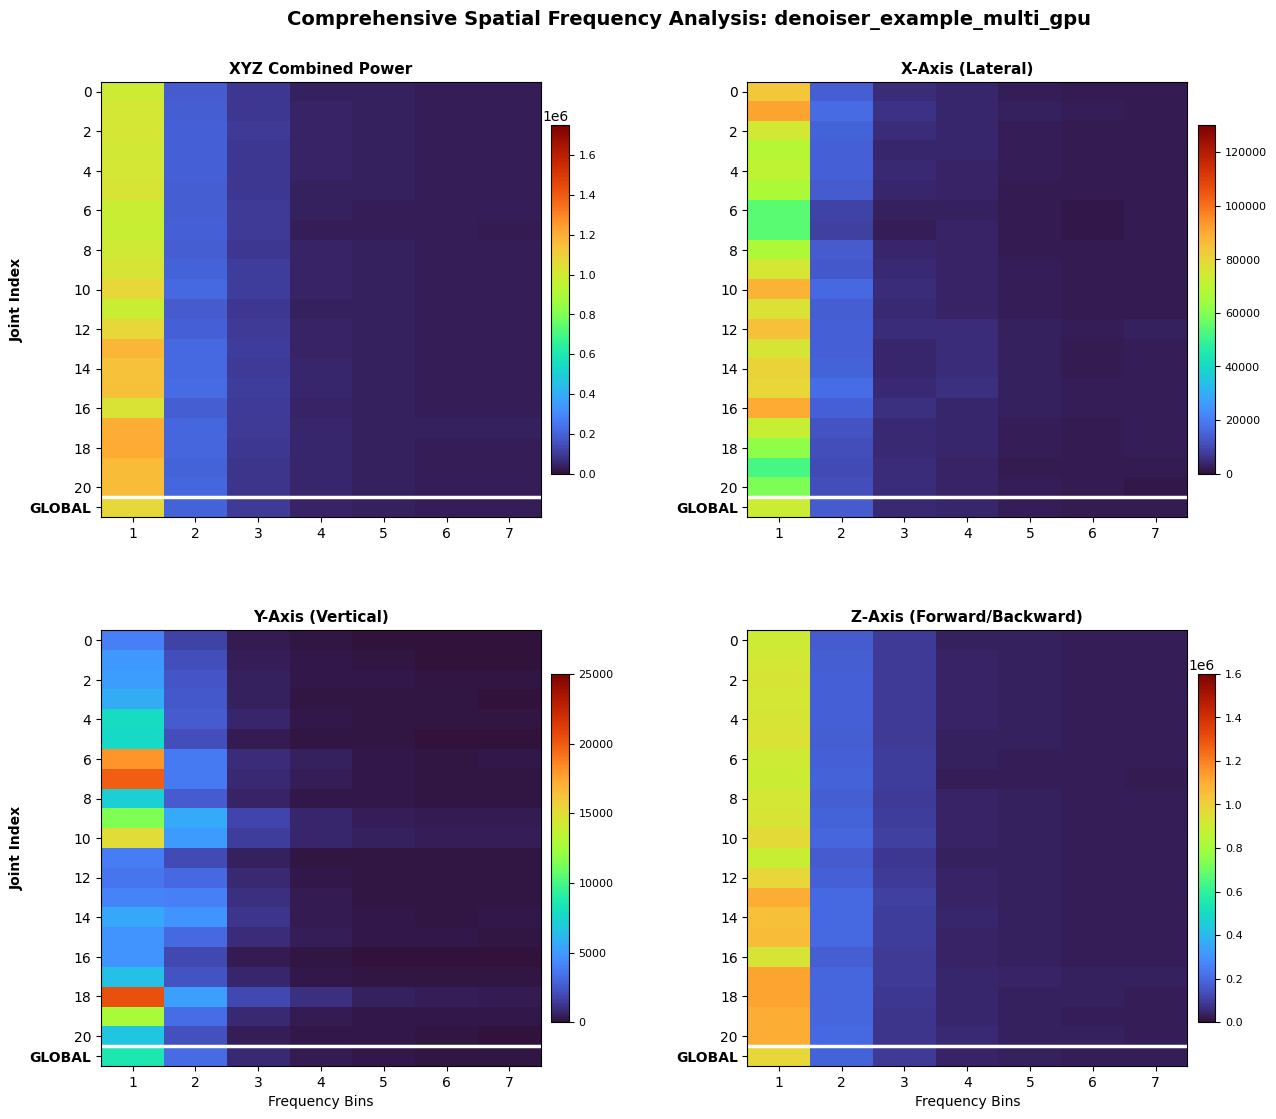

In [13]:
plot_spectrum(denoiser_name, src_motion_cl[0], wrapper_opt.joints_num, dataset_name)

Success! Complete 4-Panel Spectrum plot saved to: checkpoints/kit/denoiser_example_multi_gpu/analysis/spatial_frequency_spectrum_xyz.png


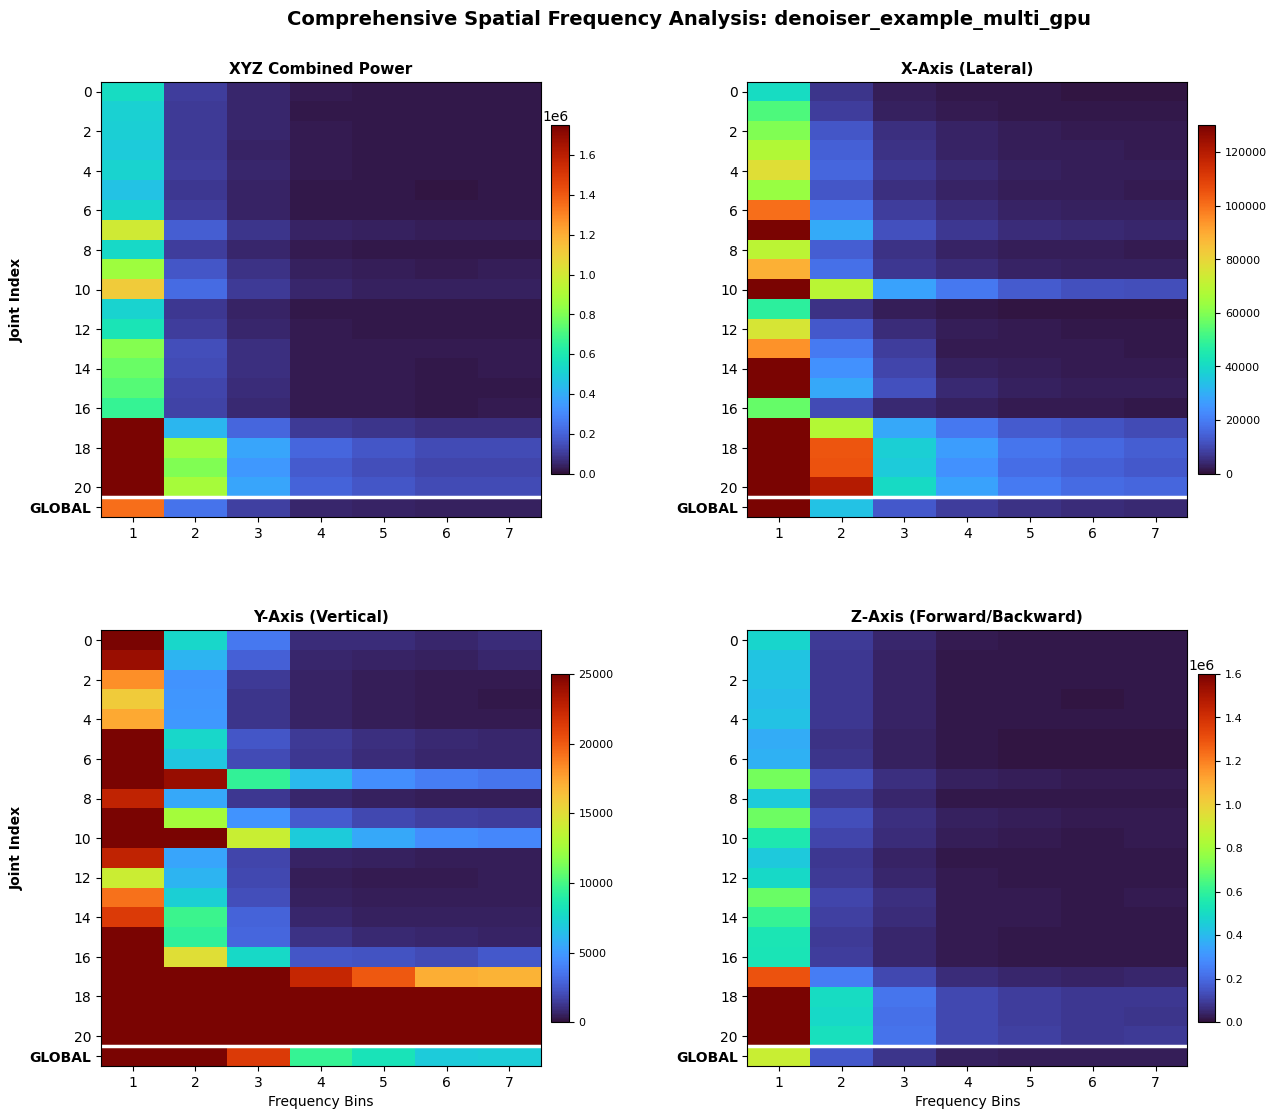

In [14]:
plot_spectrum(denoiser_name, src_motion_cl_2.squeeze(), wrapper_opt.joints_num, dataset_name)